<a href="https://colab.research.google.com/github/cozen03/2026-Programming/blob/main/%EC%97%B4_%EC%BE%8C%EC%A0%81%ED%99%94_%EA%B3%84%EC%82%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/u

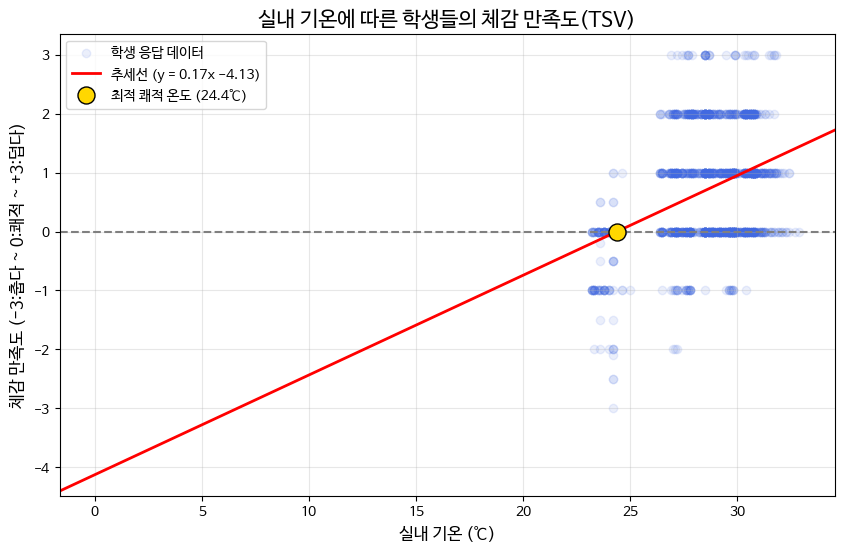

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# ★ 폰트 설정 (런타임을 다시 시작했기 때문에 이제 완벽하게 먹힙니다)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False # 마이너스(-) 기호 깨짐 방지

# 1. 데이터 불러오기
df = pd.read_csv('여름철_교실_열_쾌적성_데이터(ASHRAE).csv')

# 2. X(실내 기온), y(체감 만족도) 설정 및 AI 모델 학습
X = df['실내 기온(℃)'].values.reshape(-1, 1)
y = df['체감 만족도(TSV)'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# 3. 기울기, 절편, 최적 온도(y=0) 계산
slope = model.coef_[0]
intercept = model.intercept_
optimal_temp = -intercept / slope

# 4. 그래프 시각화
plt.figure(figsize=(10, 6))

plt.scatter(df['실내 기온(℃)'], df['체감 만족도(TSV)'], alpha=0.1, color='royalblue', label='학생 응답 데이터')
plt.axline((0, intercept), slope=slope, color='red', linewidth=2, label=f'추세선 (y = {slope:.2f}x {intercept:.2f})')
plt.scatter(optimal_temp, 0, color='gold', edgecolor='black', s=150, zorder=5, label=f'최적 쾌적 온도 ({optimal_temp:.1f}℃)')

plt.title('실내 기온에 따른 학생들의 체감 만족도(TSV)', fontsize=15)
plt.xlabel('실내 기온 (℃)', fontsize=12)
plt.ylabel('체감 만족도 (-3:춥다 ~ 0:쾌적 ~ +3:덥다)', fontsize=12)
plt.axhline(0, color='gray', linestyle='--')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()